In [2]:
from pathlib import Path
import pandas as pd

In [5]:
file = r"C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\raw\LR1865SZ_cycles201217_001_2.csv"

rows = pd.read_csv(file)
print(rows.columns.tolist())

cycle_2 = rows.loc[rows["Cycle_Index"] == 2].copy()

['Data_Point', 'Test_Time(s)', 'Current(A)', 'Capacity(Ah)', 'Voltage(V)', 'Energy(Wh)', 'Temperature(℃)', 'Date_Time', 'Cycle_Index']


In [6]:
columns = [
    "Data_Point", "Test_Time(s)", "Cycle_Index",
    "Current(A)", "Voltage(V)", "Capacity(Ah)", "Energy(Wh)",
]

cycle_parts = []
for chunk in pd.read_csv(file, usecols=columns, chunksize=50_000):
    cycle_parts.append(chunk.loc[chunk["Cycle_Index"] == 2])

cycle_2 = pd.concat(cycle_parts, ignore_index=True)

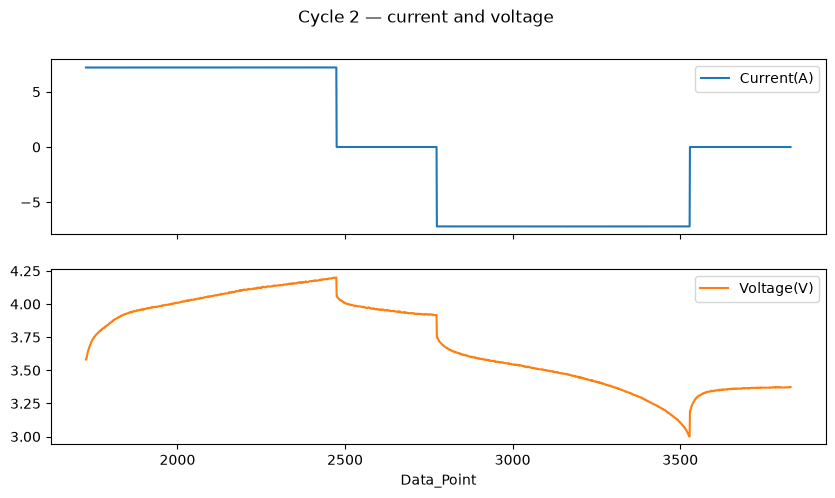

In [7]:
import matplotlib.pyplot as plt

cycle_2 = cycle_2.sort_values("Data_Point").reset_index(drop=True)

cycle_2.plot(
    x="Data_Point",
    y=["Current(A)", "Voltage(V)"],
    subplots=True,
    figsize=(10, 5),
    title="Cycle 2 — current and voltage",
)
plt.show()

In [8]:
current = cycle_2["Current(A)"]

cycle_2["phase"] = "unknown"
cycle_2.loc[current > 0, "phase"] = "charge"
cycle_2.loc[current == 0, "phase"] = "rest"
cycle_2.loc[current < 0, "phase"] = "discharge"

phase = cycle_2["phase"]
phase_changed = phase.shift().notna() & phase.ne(phase.shift())
around_change = phase_changed | phase_changed.shift(-1, fill_value=False)

display(cycle_2.loc[around_change, [
    "Data_Point", "Test_Time(s)", "phase", "Current(A)",
    "Voltage(V)", "Capacity(Ah)", "Energy(Wh)",
]]) 

,Data_Point,Test_Time(s),phase,Current(A),Voltage(V),Capacity(Ah),Energy(Wh)
747,2474,00:41:28,charge,7.205,4.2005,1.504,6.069
748,2475,00:41:28,rest,0.000,4.0582,1.504,6.069
1046,2773,00:46:28,rest,0.000,3.9156,1.504,6.069
1047,2774,00:46:28,discharge,-7.194,3.7491,0.000,0.000
1801,3528,00:59:04,discharge,-7.194,3.0001,1.512,5.202
1802,3529,00:59:04,rest,0.000,3.1901,1.512,5.202


Audit both files


In [14]:
from pathlib import Path

raw_folder = Path(
    r"C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\raw"
)

run_ids = [
    "LR1865SZ_cycles201217_001_2",
    "LR1865SZ_cycles201214_002_4",
]

runs = {}

for run_id in run_ids:
    csv_file = raw_folder / f"{run_id}.csv"
    if csv_file.is_file():
        run = pd.read_csv(csv_file)
    else:
        run = pd.read_excel(raw_folder / f"{run_id}.csv", sheet_name="记录表")

    runs[run_id] = run
    cycles = run["Cycle_Index"]
    print(f"\n{run_id}")
    print("Rows:", len(run))
    print("Columns:", run.columns.tolist())
    print(f"Cycle range: {cycles.min()}–{cycles.max()}")
    print("Distinct cycles:", cycles.nunique())
    print("Missing values by column:")
    print(run.replace("-", pd.NA).isna().sum())


LR1865SZ_cycles201217_001_2
Rows: 126648
Columns: ['Data_Point', 'Test_Time(s)', 'Current(A)', 'Capacity(Ah)', 'Voltage(V)', 'Energy(Wh)', 'Temperature(℃)', 'Date_Time', 'Cycle_Index']
Cycle range: 1–101
Distinct cycles: 101
Missing values by column:
Data_Point             0
Test_Time(s)           0
Current(A)             0
Capacity(Ah)           0
Voltage(V)             0
Energy(Wh)             0
Temperature(℃)    126648
Date_Time              0
Cycle_Index            0
dtype: int64

LR1865SZ_cycles201214_002_4
Rows: 202516
Columns: ['Data_Point', 'Test_Time(s)', 'Current(A)', 'Capacity(Ah)', 'Voltage(V)', 'Energy(Wh)', 'Temperature(℃)', 'Date_Time', 'Cycle_Index']
Cycle range: 1–101
Distinct cycles: 101
Missing values by column:
Data_Point             0
Test_Time(s)           0
Current(A)             0
Capacity(Ah)           0
Voltage(V)             0
Energy(Wh)             0
Temperature(℃)    202516
Date_Time              0
Cycle_Index            0
dtype: int64


In [15]:
for run_id, run in runs.items():
    # Convert "1-00:00:00" to "1 days 00:00:00" so pandas can read it.
    time_text = run["Test_Time(s)"].astype("string").str.strip()
    time_text = time_text.str.replace(r"^(\d+)-", r"\1 days ", regex=True)

    run["elapsed_seconds"] = pd.to_timedelta(
        time_text, errors="coerce"
    ).dt.total_seconds()

    time_gap = run["elapsed_seconds"].diff()

    print(f"\n{run_id}")
    print("Times that could not be converted:", run["elapsed_seconds"].isna().sum())
    print("Times that went backwards:", (time_gap < 0).sum())
    print("Consecutive rows with the same time:", (time_gap == 0).sum())


LR1865SZ_cycles201217_001_2
Times that could not be converted: 0
Times that went backwards: 0
Consecutive rows with the same time: 5794

LR1865SZ_cycles201214_002_4
Times that could not be converted: 0
Times that went backwards: 0
Consecutive rows with the same time: 8864


Step 3, continued — Check duplicates and time gaps

In [16]:
for run_id, run in runs.items():
    time_gap = run["elapsed_seconds"].diff()
    positive_gaps = time_gap[time_gap > 0]

    # Check duplicates using the original columns.
    raw_columns = run.columns.drop("elapsed_seconds")

    print(f"\n{run_id}")
    print("Exact duplicate rows:", run.duplicated(subset=raw_columns).sum())
    print("Repeated Data_Point values:", run["Data_Point"].duplicated().sum())

    print("\nMost common positive gaps (seconds and count):")
    print(positive_gaps.value_counts().head(5))

    print("\nFive largest gaps:")
    gap_details = run[["Data_Point", "Cycle_Index", "Test_Time(s)"]].copy()
    gap_details["previous_time"] = run["Test_Time(s)"].shift()
    gap_details["previous_cycle"] = run["Cycle_Index"].shift()
    gap_details["gap_seconds"] = time_gap
    display(gap_details.nlargest(5, "gap_seconds"))


LR1865SZ_cycles201217_001_2
Exact duplicate rows: 0
Repeated Data_Point values: 0

Most common positive gaps (seconds and count):
elapsed_seconds
1.0    114784
2.0      5828
3.0       219
4.0        19
5.0         3
Name: count, dtype: int64

Five largest gaps:


,Data_Point,Cycle_Index,Test_Time(s),previous_time,previous_cycle,gap_seconds
38426,38427,22,10:45:31,10:45:26,22.0,5.0
43202,43203,25,12:05:35,12:05:30,25.0,5.0
52293,52294,31,14:38:26,14:38:21,31.0,5.0
313,314,1,00:05:18,00:05:14,1.0,4.0
7592,7593,4,02:07:08,02:07:04,4.0,4.0



LR1865SZ_cycles201214_002_4
Exact duplicate rows: 0
Repeated Data_Point values: 0

Most common positive gaps (seconds and count):
elapsed_seconds
1.0    183892
2.0      9254
3.0       453
4.0        52
Name: count, dtype: int64

Five largest gaps:


,Data_Point,Cycle_Index,Test_Time(s),previous_time,previous_cycle,gap_seconds
1236,1237,1,00:20:59,00:20:55,1.0,4.0
2737,2738,2,00:46:28,00:46:24,2.0,4.0
3632,3633,2,01:01:36,01:01:32,2.0,4.0
13921,13922,5,03:54:55,03:54:51,5.0,4.0
25202,25203,9,07:04:42,07:04:38,9.0,4.0


Step 4 — Identify the phases in every cycle

In [17]:
for run_id, run in runs.items():
    current = pd.to_numeric(run["Current(A)"], errors="coerce")

    run["phase"] = "unknown"
    run.loc[current > 0, "phase"] = "charge"
    run.loc[current == 0, "phase"] = "rest"
    run.loc[current < 0, "phase"] = "discharge"

    cycle = run["Cycle_Index"]
    phase = run["phase"]

    new_block = cycle.ne(cycle.shift()) | phase.ne(phase.shift())

    phase_sequences = (
        run.loc[new_block, ["Cycle_Index", "phase"]]
        .groupby("Cycle_Index")["phase"]
        .agg(" → ".join)
    )

    print(f"\n{run_id}")
    print("Rows with unreadable current:", current.isna().sum())

    print("\nPhase sequences for cycles 1–3:")
    print(phase_sequences.loc[1:3].to_string())

    print("\nPhase sequence counts across all cycles:")
    print(phase_sequences.value_counts().to_string())


LR1865SZ_cycles201217_001_2
Rows with unreadable current: 0

Phase sequences for cycles 1–3:
Cycle_Index
1             rest → discharge → rest
2    charge → rest → discharge → rest
3    charge → rest → discharge → rest

Phase sequence counts across all cycles:
phase
charge → rest → discharge → rest    99
rest → discharge → rest              1
charge → rest                        1

LR1865SZ_cycles201214_002_4
Rows with unreadable current: 0

Phase sequences for cycles 1–3:
Cycle_Index
1             rest → discharge → rest
2    charge → rest → discharge → rest
3    charge → rest → discharge → rest

Phase sequence counts across all cycles:
phase
charge → rest → discharge → rest    99
rest → discharge → rest              1
charge → rest                        1


Step 5 — Build the cycle-level table

In [18]:
cycle_tables = []

for run_id, run in runs.items():
    time_bounds = run.groupby("Cycle_Index")["elapsed_seconds"].agg(
        first="min", last="max"
    )

    table = pd.DataFrame(index=time_bounds.index)
    table["run_id"] = run_id
    table["observed_duration_s"] = time_bounds["last"] - time_bounds["first"]

    for phase in ["charge", "discharge"]:
        active = run.loc[run["phase"] == phase]
        last_rows = active.drop_duplicates("Cycle_Index", keep="last")
        last_rows = last_rows.set_index("Cycle_Index")

        table[f"has_{phase}"] = table.index.isin(last_rows.index)
        table[f"{phase}_capacity_ah"] = last_rows["Capacity(Ah)"]
        table[f"{phase}_energy_wh"] = last_rows["Energy(Wh)"]
        table[f"{phase}_median_current_a"] = (
            active["Current(A)"].abs().groupby(active["Cycle_Index"]).median()
        )

    charge_ah = table["charge_capacity_ah"].where(table["charge_capacity_ah"] > 0)
    table["coulombic_efficiency_pct"] = 100 * table["discharge_capacity_ah"] / charge_ah
    table["energy_throughput_wh"] = table["charge_energy_wh"] + table["discharge_energy_wh"]

    cycle_tables.append(table.reset_index())

cycle_summary = pd.concat(cycle_tables, ignore_index=True)
print("Cycle rows:", len(cycle_summary))

incomplete = ~cycle_summary["has_charge"] | ~cycle_summary["has_discharge"]
display(cycle_summary.loc[incomplete, [
    "run_id", "Cycle_Index", "has_charge", "has_discharge",
    "charge_capacity_ah", "discharge_capacity_ah",
]])

Cycle rows: 202


,run_id,Cycle_Index,has_charge,has_discharge,charge_capacity_ah,discharge_capacity_ah
0,LR1865SZ_cycles201217_001_2,1,False,True,NaN,2.271
100,LR1865SZ_cycles201217_001_2,101,True,False,0.268,NaN
101,LR1865SZ_cycles201214_002_4,1,False,True,NaN,2.264
201,LR1865SZ_cycles201214_002_4,101,True,False,0.451,NaN


In [19]:
is_cycle_2 = (
    cycle_summary["run_id"].eq("LR1865SZ_cycles201217_001_2")
    & cycle_summary["Cycle_Index"].eq(2)
)

display(cycle_summary.loc[is_cycle_2, [
    "observed_duration_s",
    "charge_capacity_ah",
    "discharge_capacity_ah",
    "coulombic_efficiency_pct",
    "energy_throughput_wh",
]].round(3))

,observed_duration_s,charge_capacity_ah,discharge_capacity_ah,coulombic_efficiency_pct,energy_throughput_wh
1,2108.0,1.504,1.512,100.532,11.271


In [20]:
counter_columns = ["Capacity(Ah)", "Energy(Wh)"]

for run_id, run in runs.items():
    active = run.loc[run["phase"].isin(["charge", "discharge"])]

    # Each group is one charge or discharge phase within one cycle.
    phases = active.groupby(["Cycle_Index", "phase"], sort=False)
    counter_change = phases[counter_columns].diff()

    drops = counter_change.lt(0)
    affected = active.loc[drops.any(axis=1)]

    print(f"\n{run_id}")
    print("Counter decreases within a phase:")
    print(drops.sum().to_string())

    if not affected.empty:
        display(affected[[
            "Cycle_Index", "Data_Point", "phase",
            "Capacity(Ah)", "Energy(Wh)",
        ]].head())

    print("First counter readings in each phase (min and max):")
    print(phases[counter_columns].first().groupby("phase").agg(["min", "max"]))


LR1865SZ_cycles201217_001_2
Counter decreases within a phase:
Capacity(Ah)    0
Energy(Wh)      0
First counter readings in each phase (min and max):
          Capacity(Ah)      Energy(Wh)     
                   min  max        min  max
phase                                      
charge             0.0  0.0        0.0  0.0
discharge          0.0  0.0        0.0  0.0

LR1865SZ_cycles201214_002_4
Counter decreases within a phase:
Capacity(Ah)    0
Energy(Wh)      0
First counter readings in each phase (min and max):
          Capacity(Ah)      Energy(Wh)     
                   min  max        min  max
phase                                      
charge             0.0  0.0        0.0  0.0
discharge          0.0  0.0        0.0  0.0


Step 5, continued — Add C-rate

In [24]:
# Replace None with the confirmed nominal capacity in Ah for each run.
nominal_capacity_by_run = {
    "LR1865SZ_cycles201217_001_2": 2.5,
    "LR1865SZ_cycles201214_002_4": 2.5,
}

nominal_ah = pd.to_numeric(
    cycle_summary["run_id"].map(nominal_capacity_by_run)
)
cycle_summary["nominal_capacity_ah"] = nominal_ah.where(nominal_ah > 0)

for phase in ["charge", "discharge"]:
    cycle_summary[f"{phase}_c_rate"] = (
        cycle_summary[f"{phase}_median_current_a"]
        / cycle_summary["nominal_capacity_ah"]
    )

In [25]:
display(cycle_summary[[
    "run_id",
    "Cycle_Index",
    "nominal_capacity_ah",
    "charge_c_rate",
    "discharge_c_rate",
]].head(10))

,run_id,Cycle_Index,nominal_capacity_ah,charge_c_rate,discharge_c_rate
0,LR1865SZ_cycles201217_001_2,1,2.5,NaN,2.8784
1,LR1865SZ_cycles201217_001_2,2,2.5,2.8796,2.8784
2,LR1865SZ_cycles201217_001_2,3,2.5,2.8784,2.8784
3,LR1865SZ_cycles201217_001_2,4,2.5,2.8796,2.8784
4,LR1865SZ_cycles201217_001_2,5,2.5,2.8804,2.8804
5,LR1865SZ_cycles201217_001_2,6,2.5,2.8804,2.8784
6,LR1865SZ_cycles201217_001_2,7,2.5,2.8804,2.8784
7,LR1865SZ_cycles201217_001_2,8,2.5,2.8784,2.8784
8,LR1865SZ_cycles201217_001_2,9,2.5,2.8804,2.8804
9,LR1865SZ_cycles201217_001_2,10,2.5,2.8804,2.8784


In [26]:
processed_folder = raw_folder.parent / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

measurements = pd.concat(
    [run.assign(run_id=run_id) for run_id, run in runs.items()],
    ignore_index=True,
)

measurements.to_csv(processed_folder / "measurements_clean.csv", index=False)
cycle_summary.to_csv(processed_folder / "cycle_summary.csv", index=False)

print("Saved both CSVs in:", processed_folder)

Saved both CSVs in: C:\Users\suman\Documents\meatech-battery-analytics-case-study\data\processed
